# The Feller condition and numerical methods

**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

**Question.** If the Feller condition does not hold, which numerical methods work and which do not?

This notebook answers the question: it contains the minimum theory, seven Monte Carlo methods programmed, four experiments and the conclusions (section 7).

| Section | What it does |
|---|---|
| 1 | What the Feller condition is and what happens to the variance when it does not hold |
| 2 | The simulation schemes (every line commented) |
| 3 | Experiment 1: bias of each method as the Feller ratio falls (book parameters) |
| 4 | Experiment 2: does the bias disappear if we take more steps? |
| 5 | Experiment 3: with the parameters calibrated to the S&P 500 |
| 6 | Experiment 4: is the problem Feller or a large ν? (φ falls by reducing κ) |
| 7 | Conclusions |
| 8 | References |

**How to run it:** *Run All* in VS Code, or `py -m nbconvert --to notebook --execute --inplace feller_monte_carlo.ipynb`. It takes about 8 minutes on a laptop.

## 1. What is the Feller condition?

In Heston, the variance v_t follows the process (CIR process, from Cox, Ingersoll and Ross, 1985):

  dv_t = κ(θ − v_t) dt + ν √v_t dW_t

When v_t approaches 0 there are two forces: the **drift** κ(θ − v_t), which near 0 is ≈ κθ > 0 and pushes upwards, and the **noise** ν√v_t dW_t, which becomes small but can push downwards. **Feller (1951)** proved that:

- if **2κθ ≥ ν²**, the drift wins and v_t **never reaches 0**;
- if **2κθ < ν²**, v_t **can reach 0** (and leaves it immediately, because the drift is positive).

We summarise it with the **Feller ratio φ = 2κθ/ν²**: the condition holds if φ ≥ 1. In the S&P 500 calibration we get φ ≈ 0.15–0.25, far below 1.

**The exact distribution.** We know the distribution of v_{t+Δ} given v_t: v_{t+Δ} = c·X, where X is a non-central chi-squared with **d = 4κθ/ν² = 2φ degrees of freedom**, c = ν²(1 − e^(−κΔ))/(4κ) and non-centrality parameter λ = v_t e^(−κΔ)/c. Therefore, Feller holds if and only if d ≥ 2. When d < 2, the density of v near 0 blows up (it behaves like v^(φ−1)): the process spends a lot of time near 0.

**Why does it matter numerically?**
1. Discretisation schemes such as Euler can give **negative variances**, and then √v does not exist. Each way of fixing it introduces a different **bias**.
2. When φ < 1, the process spends a lot of time near 0, which is exactly where the schemes fail most.
3. The Fourier formula and the decomposition formula do not simulate paths; we need to check whether they are also affected.

The next cell plots the **exact** density of v_T (T = 1 year) for different φ. We lower φ by raising ν; κ, θ and v0 are those of the book. Notice that the **mean** of v_T does not depend on ν, but the shape changes a lot.

Feller ratio of the book: φ = 2.00  (it holds)
φ =    2: P(v_T < 0.001) = 0.000;  mean 0.0718 (theoretical 0.0716)
φ =    1: P(v_T < 0.001) = 0.013;  mean 0.0714 (theoretical 0.0716)


φ =  0.5: P(v_T < 0.001) = 0.093;  mean 0.0714 (theoretical 0.0716)
φ = 0.25: P(v_T < 0.001) = 0.266;  mean 0.0715 (theoretical 0.0716)


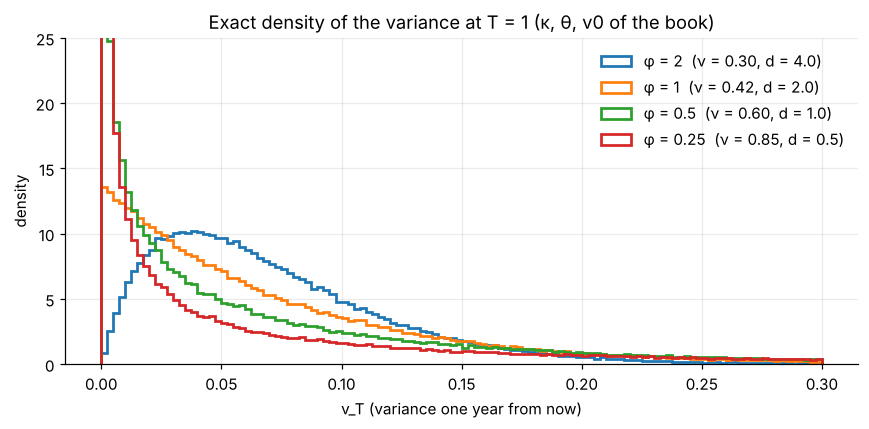

In [1]:
# --- Libraries ---
import time                                       # to measure how long each method takes
import numpy as np                                # computation with vectors (all paths at once)
import pandas as pd                               # result tables
import matplotlib.pyplot as plt                   # plots
import heston_tfg as ht                           # Heston price by Fourier and decomposition formula (benchmarks)
from heston_experiment import heston_mc_conditional   # the book's conditional Monte Carlo (heston_experiment.py)

pd.set_option("display.width", 220)               # wide tables
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110})

# --- Experiment of the chapter (the same one replicated in the first exercise) ---
S0, K, T, R = 100.0, 100.0, 1.0, 0.0              # initial price, strike, maturity (years), interest rate
BOOK = {"kappa": 1.0, "theta": 0.09, "nu": 0.3, "rho": -0.5, "v0": 0.04}     # Heston parameters of the book
N = 200_000                                       # number of paths of each Monte Carlo
SEED = 1                                          # same seed for all methods: same random numbers,
                                                  # so the differences between methods are not simulation noise


def feller_ratio(p):
    """φ = 2κθ/ν². The Feller condition holds if φ ≥ 1."""
    return 2 * p["kappa"] * p["theta"] / p["nu"] ** 2


def with_ratio(p, phi):
    """Copy of p with the ν that gives the Feller ratio φ (κ, θ and the rest do not change): ν = √(2κθ/φ)."""
    return dict(p, nu=np.sqrt(2 * p["kappa"] * p["theta"] / phi))


print(f"Feller ratio of the book: φ = {feller_ratio(BOOK):.2f}  (it holds)")

# --- Exact density of v_T for different φ ---
rng = np.random.default_rng(0)                    # random number generator
fig, ax = plt.subplots(figsize=(8, 4))
for phi in [2, 1, 0.5, 0.25]:
    p = with_ratio(BOOK, phi)                     # parameters with this Feller ratio
    e = np.exp(-p["kappa"] * T)                   # e^(-κT)
    c = p["nu"] ** 2 * (1 - e) / (4 * p["kappa"]) # scale factor c
    d = 4 * p["kappa"] * p["theta"] / p["nu"] ** 2    # degrees of freedom d = 2φ
    lam = p["v0"] * e / c                         # non-centrality λ
    vT = c * rng.noncentral_chisquare(d, lam, size=N)  # EXACT sample of v_T (without discretising)
    ax.hist(vT, bins=np.linspace(0, 0.3, 121), density=True, histtype="step", lw=1.8,
            label=f"φ = {phi}  (ν = {p['nu']:.2f}, d = {d:.1f})")
    theoretical_mean = p["theta"] + (p["v0"] - p["theta"]) * e   # E[v_T] = θ + (v0 − θ) e^(−κT)
    print(f"φ = {phi:4}: P(v_T < 0.001) = {np.mean(vT < 0.001):.3f};  mean {vT.mean():.4f} (theoretical {theoretical_mean:.4f})")
ax.set_xlabel("v_T (variance one year from now)"); ax.set_ylabel("density"); ax.set_ylim(0, 25)
ax.set_title("Exact density of the variance at T = 1 (κ, θ, v0 of the book)"); ax.legend()
plt.tight_layout(); plt.savefig("fig_density_vT.png", dpi=150); plt.show()

## 2. The simulation schemes

All of them simulate N paths at once in m steps of size Δ = T/m. Z₁, Z₂ are independent standard normals. The correlation between the price and the variance is introduced with ρZ₁ + √(1 − ρ²)Z₂.

**(a) Euler family (Lord, Koekkoek and van Dijk, 2010).** They use an auxiliary process x that **can** be negative:

  x_{n+1} = f₁(x_n) + κ(θ − f₂(x_n))Δ + ν √(f₃(x_n)Δ) Z₁,  and the variance used is v_n = f₃(x_n).

| Variant | f₁ | f₂ | f₃ |
|---|---|---|---|
| Absorption | max(x, 0) | max(x, 0) | max(x, 0) |
| Reflection | \|x\| | \|x\| | \|x\| |
| Full truncation | x | max(x, 0) | max(x, 0) |

The price is simulated in logarithms: ln S_{n+1} = ln S_n + (r − v_n/2)Δ + √(v_n Δ)(ρZ₁ + √(1−ρ²)Z₂).

**(b) Milstein with reflection.** It is the scheme of the book's conditional Monte Carlo (`heston_experiment.py`): it adds the Milstein term ¼ν²(ΔW² − Δ), with ΔW = √Δ·Z₁, and, if the result is negative, takes its absolute value.

**(c) QE, *quadratic-exponential* (Andersen, 2008).** It does not discretise the equation: at each step it generates v_{n+1} with a distribution that has **the same mean and variance** as the exact distribution. If the relative variance ψ = s²/m² is small, it uses a(b + Z)² (a squared normal); if it is large, a distribution with a probability mass at 0 and an exponential tail. It never gives negative values.

**(d) Exact chi-squared for v.** It generates v_{n+1} with the exact distribution (section 1). It is the first step of the exact simulation of Broadie and Kaya (2006).

For (c) and (d), the price is updated with Andersen's formula (2008, eq. 33), which comes from eliminating ∫√v dW with the variance equation and approximating ∫v dt by the trapezoidal rule:

  ln S_{n+1} = ln S_n + rΔ + K₀ + K₁v_n + K₂v_{n+1} + √(K₃v_n + K₄v_{n+1})·Z, with K₀ = −ρκθΔ/ν, K₁ = ½Δ(κρ/ν − ½) − ρ/ν, K₂ = ½Δ(κρ/ν − ½) + ρ/ν, K₃ = K₄ = ½Δ(1 − ρ²).

**(e) The book's conditional Monte Carlo** (`heston_mc_conditional` in `heston_experiment.py`): it only simulates the variance (Milstein with reflection) and integrates the price with the Black-Scholes formula. It has much less noise, but it uses the same scheme for v as (b).

**Benchmark:** the Heston price by **Fourier** (`ht.heston_call_fwd`). We also compare the **decomposition formula** (`ht.decomp_call_fwd`).

In [2]:
def euler(p, m, rng, variant):
    """Euler scheme for (ln S, x) with the three ways of avoiding √(negative) of Lord et al. (2010).
    Returns (S_T of each path, fraction of steps in which x became negative)."""
    k, th, nu, rho, v0 = p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"]   # parameters
    dt = T / m                                                     # step size
    x = np.full(N, v0)                                             # auxiliary process (can be negative)
    lnS = np.full(N, np.log(S0))                                   # logarithm of the price
    negatives = 0                                                  # counter of negative values
    for _ in range(m):                                             # we move forward step by step
        z1 = rng.standard_normal(N)                                # noise of the variance
        z2 = rng.standard_normal(N)                                # independent noise for the price
        if variant == "absorption":                                # f1 = f2 = f3 = max(x, 0)
            f1 = f2 = f3 = np.maximum(x, 0)
        elif variant == "reflection":                              # f1 = f2 = f3 = |x|
            f1 = f2 = f3 = np.abs(x)
        else:                                                      # full truncation: f1 = x, f2 = f3 = max(x, 0)
            f1, f2, f3 = x, np.maximum(x, 0), np.maximum(x, 0)
        v = f3                                                     # variance used by the price
        lnS = lnS + (R - 0.5 * v) * dt + np.sqrt(v * dt) * (rho * z1 + np.sqrt(1 - rho ** 2) * z2)   # price step
        x = f1 + k * (th - f2) * dt + nu * np.sqrt(f3 * dt) * z1   # Euler step of the variance
        negatives += np.sum(x < 0)                                 # how many became negative
    return np.exp(lnS), negatives / (N * m)


def milstein_reflection(p, m, rng):
    """Milstein for v with reflection (like the book's conditional Monte Carlo), but also simulating the price."""
    k, th, nu, rho, v0 = p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"]
    dt = T / m
    v = np.full(N, v0)                                             # variance (always ≥ 0 thanks to reflection)
    lnS = np.full(N, np.log(S0))
    negatives = 0
    for _ in range(m):
        z1 = rng.standard_normal(N)
        z2 = rng.standard_normal(N)
        lnS = lnS + (R - 0.5 * v) * dt + np.sqrt(v * dt) * (rho * z1 + np.sqrt(1 - rho ** 2) * z2)   # price step
        dW = np.sqrt(dt) * z1                                      # Brownian increment
        v_new = v + k * (th - v) * dt + nu * np.sqrt(v) * dW + 0.25 * nu ** 2 * (dW ** 2 - dt)   # Milstein
        negatives += np.sum(v_new < 0)                             # how many come out negative before reflecting
        v = np.abs(v_new)                                          # reflection: if it is negative, we take its absolute value
    return np.exp(lnS), negatives / (N * m)


def andersen_price_step(lnS, v, v_new, p, dt, z):
    """Log-price step given v_n and v_{n+1} (Andersen 2008, eq. 33, with γ1 = γ2 = 1/2: trapezoidal rule)."""
    k, th, nu, rho = p["kappa"], p["theta"], p["nu"], p["rho"]
    K0 = -rho * k * th * dt / nu
    K1 = 0.5 * dt * (k * rho / nu - 0.5) - rho / nu
    K2 = 0.5 * dt * (k * rho / nu - 0.5) + rho / nu
    K3 = K4 = 0.5 * dt * (1 - rho ** 2)
    return lnS + R * dt + K0 + K1 * v + K2 * v_new + np.sqrt(K3 * v + K4 * v_new) * z


def qe(p, m, rng, psi_c=1.5):
    """Andersen's (2008) QE scheme. Returns (S_T, fraction of steps in which v ended up exactly at 0)."""
    k, th, nu, v0 = p["kappa"], p["theta"], p["nu"], p["v0"]
    dt = T / m
    e = np.exp(-k * dt)                                            # e^(-κΔ)
    v = np.full(N, v0)
    lnS = np.full(N, np.log(S0))
    zeros = 0
    for _ in range(m):
        mean = th + (v - th) * e                                   # E[v_{n+1} | v_n] (exact)
        s2 = v * nu ** 2 * e * (1 - e) / k + th * nu ** 2 * (1 - e) ** 2 / (2 * k)   # Var[v_{n+1} | v_n] (exact)
        psi = s2 / mean ** 2                                       # relative variance ψ
        zv = rng.standard_normal(N)                                # for the quadratic branch
        u = rng.uniform(size=N)                                    # for the exponential branch
        v_new = np.empty(N)
        q = psi <= psi_c                                           # which paths go through the quadratic branch
        b2 = 2 / psi[q] - 1 + np.sqrt(2 / psi[q]) * np.sqrt(2 / psi[q] - 1)   # b² (matches mean and variance)
        a = mean[q] / (1 + b2)                                     # a
        v_new[q] = a * (np.sqrt(b2) + zv[q]) ** 2                  # quadratic branch: a(b + Z)²
        pr = (psi[~q] - 1) / (psi[~q] + 1)                         # probability of v_{n+1} = 0
        beta = (1 - pr) / mean[~q]                                 # parameter of the exponential tail
        uu = u[~q]
        v_new[~q] = np.where(uu <= pr, 0.0, np.log((1 - pr) / np.maximum(1 - uu, 1e-300)) / beta)   # exponential branch
        zeros += np.sum(v_new == 0)
        lnS = andersen_price_step(lnS, v, v_new, p, dt, rng.standard_normal(N))
        v = v_new
    return np.exp(lnS), zeros / (N * m)


def exact_chi2(p, m, rng):
    """v_{n+1} with the exact distribution (non-central chi-squared) and the price with Andersen's formula."""
    k, th, nu, v0 = p["kappa"], p["theta"], p["nu"], p["v0"]
    dt = T / m
    e = np.exp(-k * dt)
    c = nu ** 2 * (1 - e) / (4 * k)                                # scale
    d = 4 * k * th / nu ** 2                                       # degrees of freedom (= 2φ)
    v = np.full(N, v0)
    lnS = np.full(N, np.log(S0))
    for _ in range(m):
        v_new = c * rng.noncentral_chisquare(d, v * e / c)         # exact sample of v_{n+1} given v_n
        lnS = andersen_price_step(lnS, v, v_new, p, dt, rng.standard_normal(N))
        v = v_new
    return np.exp(lnS), np.nan                                     # here there are no negatives by definition


SCHEMES = {                                                        # name -> function (p, m, rng)
    "Euler + absorption": lambda p, m, rng: euler(p, m, rng, "absorption"),
    "Euler + reflection": lambda p, m, rng: euler(p, m, rng, "reflection"),
    "Euler + full truncation": lambda p, m, rng: euler(p, m, rng, "truncation"),
    "Milstein + reflection": milstein_reflection,
    "QE (Andersen)": qe,
    "Exact chi² for v": exact_chi2,
}

In [3]:
def evaluate(p, m):
    """Price of a call (S0, K, T) with each method and comparison with Fourier.
    bias_vol = (implied vol of the method − implied vol of Fourier) in points; z = price bias / standard error."""
    F = S0 * np.exp(R * T)                                         # forward
    args = (T, R, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])
    ref = float(ht.heston_call_fwd(F, [K], *args)[0])              # benchmark price (Fourier)
    iv_ref = ht.implied_vol_fwd(ref, F, K, T, R)                   # its implied volatility
    vega = ht.bs_vega_fwd(F, K, T, iv_ref, R)                      # vega, to turn price errors into volatility errors
    rows = []

    def add(name, price, se, frac, seconds):                       # adds a row to the results table
        rows.append(dict(method=name, phi=feller_ratio(p), m=m, price=price,
                         bias_vol=100 * (ht.implied_vol_fwd(price, F, K, T, R) - iv_ref),
                         se_vol=100 * se / vega, z=(price - ref) / se if se > 0 else np.nan,
                         frac_problem=frac, seconds=seconds))

    for name, scheme in SCHEMES.items():                           # the 6 full-simulation schemes
        t0 = time.time()
        ST, frac = scheme(p, m, np.random.default_rng(SEED))       # S_T of the N paths
        payoff = np.exp(-R * T) * np.maximum(ST - K, 0)            # discounted payoff of the call
        add(name, payoff.mean(), payoff.std(ddof=1) / np.sqrt(N), frac, time.time() - t0)
    t0 = time.time()                                               # the book's conditional Monte Carlo
    price, se = heston_mc_conditional(S0, K, p["v0"], R, T, p["kappa"], p["theta"], p["nu"], p["rho"], m, N, seed=SEED)
    add("Book's conditional (Milstein + reflection)", price, se, np.nan, time.time() - t0)
    t0 = time.time()                                               # decomposition formula (not Monte Carlo: se = 0)
    add("Decomposition formula", float(ht.decomp_call_fwd(F, [K], *args)[0]), 0.0, np.nan, time.time() - t0)
    return pd.DataFrame(rows), ref

## 3. Experiment 1: what happens when the Feller ratio falls?

Book parameters (φ = 2), and we raise ν so that φ falls: 2 → 1 → 0.5 → 0.25 → 0.1. We take m = 52 steps (one per week) and N = 200,000 paths.

How to read the table: **bias_vol** is the error of the method in implied-volatility points; **z** = price error / standard error. If |z| < 2, the error is compatible with Monte Carlo noise; if |z| is large, the method has a **bias**. **frac_problem** is the fraction of steps in which the variance became negative (Euler and Milstein) or exactly 0 (QE).

In [4]:
t0 = time.time()
res1 = []
for phi in [2, 1, 0.5, 0.25, 0.1]:                                 # from "Feller holds comfortably" to "badly violated"
    table, ref = evaluate(with_ratio(BOOK, phi), m=52)
    res1.append(table)
    print(f"φ = {phi:4}: ν = {np.sqrt(2 * BOOK['kappa'] * BOOK['theta'] / phi):.3f}, Fourier price = {ref:.4f}")
res1 = pd.concat(res1)
print(f"Time: {time.time() - t0:.0f} s\n")
print("Bias in volatility points (columns: φ)")
display(res1.pivot(index="method", columns="phi", values="bias_vol").iloc[:, ::-1].round(3))
print("z = bias / standard error")
display(res1.pivot(index="method", columns="phi", values="z").iloc[:, ::-1].round(1))
print("Fraction of steps with negative variance (Euler, Milstein) or exactly 0 (QE)")
display(res1.dropna(subset=["frac_problem"]).pivot(index="method", columns="phi", values="frac_problem").iloc[:, ::-1].round(4))

φ =    2: ν = 0.300, Fourier price = 9.2264


φ =    1: ν = 0.424, Fourier price = 8.9374


φ =  0.5: ν = 0.600, Fourier price = 8.4741


φ = 0.25: ν = 0.849, Fourier price = 7.8141


φ =  0.1: ν = 1.342, Fourier price = 6.6915
Time: 40 s

Bias in volatility points (columns: φ)


phi,2.00,1.00,0.50,0.25,0.10
method,,,,,
Book's conditional (Milstein + reflection),-0.099,-0.080,-0.064,1.734,9.504
Decomposition formula,-0.025,-0.125,-0.540,-1.934,-8.000
Euler + absorption,0.007,0.093,0.628,2.265,6.656
Euler + full truncation,0.006,0.029,0.053,0.223,0.724
Euler + reflection,0.009,0.165,1.229,4.508,13.651
Exact chi² for v,-0.025,-0.097,0.013,-0.100,0.059
Milstein + reflection,0.001,0.022,0.028,1.805,9.550
QE (Andersen),0.021,0.036,0.057,0.039,0.030


z = bias / standard error


phi,2.00,1.00,0.50,0.25,0.10
method,,,,,
Book's conditional (Milstein + reflection),-4.0,-4.0,-4.1,115.2,474.3
Decomposition formula,NaN,NaN,NaN,NaN,NaN
Euler + absorption,0.1,1.2,8.4,29.7,76.6
Euler + full truncation,0.1,0.4,0.7,3.2,10.3
Euler + reflection,0.1,2.2,16.1,53.7,121.9
Exact chi² for v,-0.3,-1.3,0.2,-1.4,0.9
Milstein + reflection,0.0,0.3,0.4,23.9,97.9
QE (Andersen),0.3,0.5,0.8,0.6,0.4


Fraction of steps with negative variance (Euler, Milstein) or exactly 0 (QE)


phi,2.00,1.00,0.50,0.25,0.10
method,,,,,
Euler + absorption,0.0003,0.0075,0.0362,0.0834,0.1459
Euler + full truncation,0.0004,0.0117,0.0754,0.2213,0.4781
Euler + reflection,0.0004,0.0075,0.0359,0.0800,0.1310
Milstein + reflection,0.0000,0.0000,0.0122,0.1531,0.2493
QE (Andersen),0.0000,0.0000,0.0312,0.1973,0.5175


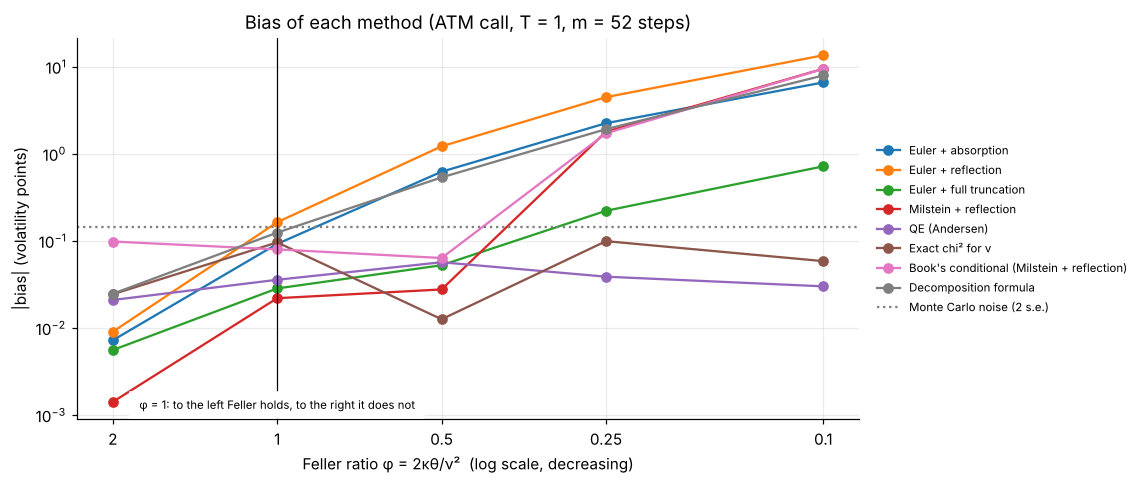

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.5))
for name, g in res1.groupby("method", sort=False):
    ax.plot(g["phi"], g["bias_vol"].abs(), "o-", label=name)       # |bias| of each method as a function of φ
noise = 2 * res1[res1["method"] == "Exact chi² for v"]["se_vol"].mean()   # 2 typical standard errors
ax.axhline(noise, color="gray", ls=":", label="Monte Carlo noise (2 s.e.)")   # below it: indistinguishable from 0
ax.axvline(1, color="k", lw=0.8)                                   # φ = 1: Feller boundary
ax.text(1.0, 0.02, " φ = 1: to the left Feller holds, to the right it does not ", transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=7.5, backgroundcolor="white")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis()      # to the right, smaller φ (more violation)
ax.set_xticks([2, 1, 0.5, 0.25, 0.1]); ax.set_xticklabels(["2", "1", "0.5", "0.25", "0.1"]); ax.minorticks_off()
ax.set_xlabel("Feller ratio φ = 2κθ/ν²  (log scale, decreasing)"); ax.set_ylabel("|bias| (volatility points)")
ax.set_title("Bias of each method (ATM call, T = 1, m = 52 steps)")
ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5))   # legend outside the plot
plt.tight_layout(); plt.savefig("fig_bias_vs_feller.png", dpi=150); plt.show()

## 4. Experiment 2: if we take more steps, does the bias disappear?

A discretisation bias should decrease as the step Δ becomes small. We fix φ = 0.25 (Feller badly violated, similar to what comes out with real data) and try m = 12 (monthly), 26, 52 (weekly), 104 and 252 (daily) steps.

Time: 69 s

Bias in volatility points (columns: number of steps m)


m,12,26,52,104,252
method,,,,,
Book's conditional (Milstein + reflection),3.081,2.248,1.734,1.428,1.092
Decomposition formula,-1.934,-1.934,-1.934,-1.934,-1.934
Euler + absorption,3.698,2.878,2.265,1.722,1.319
Euler + full truncation,1.006,0.484,0.223,0.042,0.039
Euler + reflection,7.515,5.846,4.508,3.435,2.526
Exact chi² for v,0.070,0.079,-0.100,0.080,0.077
Milstein + reflection,3.223,2.348,1.805,1.413,1.113
QE (Andersen),0.030,0.003,0.039,0.047,0.009


z = bias / standard error


m,12,26,52,104,252
method,,,,,
Book's conditional (Milstein + reflection),140.7,128.9,115.2,104.5,85.8
Decomposition formula,NaN,NaN,NaN,NaN,NaN
Euler + absorption,45.1,36.5,29.7,23.2,17.9
Euler + full truncation,13.6,6.7,3.2,0.6,0.6
Euler + reflection,76.2,64.8,53.7,43.1,32.8
Exact chi² for v,1.0,1.1,-1.4,1.1,1.1
Milstein + reflection,38.8,29.9,23.9,19.2,15.2
QE (Andersen),0.4,0.0,0.6,0.7,0.1


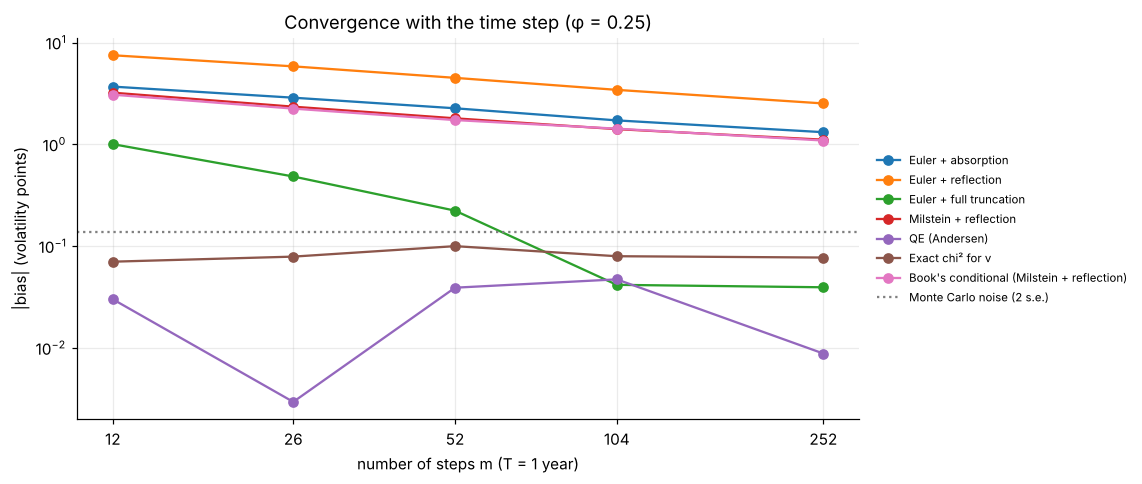

In [6]:
t0 = time.time()
p025 = with_ratio(BOOK, 0.25)                                      # φ = 0.25
res2 = pd.concat([evaluate(p025, m)[0] for m in [12, 26, 52, 104, 252]])
print(f"Time: {time.time() - t0:.0f} s\n")
print("Bias in volatility points (columns: number of steps m)")
display(res2.pivot(index="method", columns="m", values="bias_vol").round(3))
print("z = bias / standard error")
display(res2.pivot(index="method", columns="m", values="z").round(1))

fig, ax = plt.subplots(figsize=(10.5, 4.5))
for name, g in res2.groupby("method", sort=False):
    if name != "Decomposition formula":                            # the formula has no steps
        ax.plot(g["m"], g["bias_vol"].abs(), "o-", label=name)
ax.axhline(2 * res2["se_vol"][res2["method"] == "Exact chi² for v"].mean(), color="gray", ls=":",
           label="Monte Carlo noise (2 s.e.)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([12, 26, 52, 104, 252]); ax.set_xticklabels(["12", "26", "52", "104", "252"]); ax.minorticks_off()
ax.set_xlabel("number of steps m (T = 1 year)"); ax.set_ylabel("|bias| (volatility points)")
ax.set_title("Convergence with the time step (φ = 0.25)")
ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.savefig("fig_convergence_steps.png", dpi=150); plt.show()

## 5. Experiment 3: with the parameters calibrated to the S&P 500

We use the parameters of the global calibration of 12/10 (`calibration_by_maturity.ipynb`): κ = 9.54, θ = 0.0386, ν = 1.94, ρ = −0.605, v0 = 0.0096, that is, φ ≈ 0.20. Maturity of 3 months, ATM call, with weekly steps (13) and daily steps (91, calendar days). It is the case that matters for the thesis: if we want to validate a price with Monte Carlo, which method and how many steps do we need?

In [7]:
REAL = {"kappa": 9.5423, "theta": 0.0386, "nu": 1.9396, "rho": -0.605, "v0": 0.0096}   # global calibration 12/10 (calibration_by_maturity.ipynb)
T_book = T                                                         # we save the maturity of the book...
T = 91 / 365                                                       # ...and set one of 3 months (the functions use the global T)
t0 = time.time()
try:
    res3 = pd.concat([evaluate(REAL, m)[0] for m in [13, 91]])
finally:                                                           # whatever happens, we set T = 1 again
    T = T_book                                                     # (in case other cells are run again later)
print(f"φ = {feller_ratio(REAL):.3f};  time: {time.time() - t0:.0f} s")
display(res3.pivot(index="method", columns="m", values=["bias_vol", "z", "frac_problem", "seconds"]).round(3))

φ = 0.196;  time: 17 s


bias_vol               z          frac_problem        seconds       
m                                                13     91       13       91           13     91      13     91
method                                                                                                         
Book's conditional (Milstein + reflection)    6.494  3.423  256.836  241.697          NaN    NaN   0.220  0.902
Decomposition formula                        -1.776 -1.776      NaN      NaN          NaN    NaN   0.000  0.000
Euler + absorption                            4.695  3.134   86.496   65.042        0.189  0.111   0.234  1.395
Euler + full truncation                       1.155  0.128   26.399    3.225        0.412  0.320   0.196  1.619
Euler + reflection                           10.019  6.186  132.415  106.626        0.211  0.103   0.179  1.393
Exact chi² for v                              0.109  0.032    2.730    0.811          NaN    NaN   0.620  2.882
Milstein + reflection                         6.661  3.442  104.445   69.207        0.371  0.208   0.208  1.627
QE (Andersen)                                 0.075 -0.040    1.907   -1.018        0.493  0.328   0.669  4.355

## 6. Experiment 4: is the problem Feller or a large ν?

In experiment 1, φ = 2κθ/ν² falls because **ν rises** (from 0.30 to 1.34). This way we cannot know whether the biases come from the violation of Feller or simply from ν being large. Here we lower φ through the same values (2, 1, 0.5, 0.25 and 0.1) by **reducing κ** and keeping **ν = 0.3** fixed: κ = φν²/(2θ), that is, κ = 1; 0.5; 0.25; 0.125 and 0.05. The rest (θ, ρ, v0, the ATM call, T = 1, m = 52 steps, N = 200,000 paths and the seed) is the same as in experiment 1.

If the bias of a method depends only on φ, it must come out the same as in experiment 1. If it depends mostly on ν, it must be much smaller.

In [8]:
t0 = time.time()
res4 = []
for phi in [2, 1, 0.5, 0.25, 0.1]:
    p = dict(BOOK, kappa=phi * BOOK["nu"] ** 2 / (2 * BOOK["theta"]))     # κ = φν²/(2θ): φ falls by reducing κ, with ν = 0.3
    table, ref = evaluate(p, m=52)
    res4.append(table)
    print(f"φ = {phi:4}: κ = {p['kappa']:.3f}, Fourier price = {ref:.4f}")
res4 = pd.concat(res4)
print(f"Time: {time.time() - t0:.0f} s\n")
print("Bias in volatility points (columns: φ)")
display(res4.pivot(index="method", columns="phi", values="bias_vol").iloc[:, ::-1].round(3))
print("z = bias / standard error")
display(res4.pivot(index="method", columns="phi", values="z").iloc[:, ::-1].round(1))

φ =    2: κ = 1.000, Fourier price = 9.2264


φ =    1: κ = 0.500, Fourier price = 8.4265


φ =  0.5: κ = 0.250, Fourier price = 7.8635


φ = 0.25: κ = 0.125, Fourier price = 7.5180


φ =  0.1: κ = 0.050, Fourier price = 7.2830
Time: 34 s

Bias in volatility points (columns: φ)


phi,2.00,1.00,0.50,0.25,0.10
method,,,,,
Book's conditional (Milstein + reflection),-0.099,-0.066,-0.031,0.056,0.178
Decomposition formula,-0.025,-0.066,-0.096,-0.111,-0.117
Euler + absorption,0.007,0.047,0.110,0.176,0.232
Euler + full truncation,0.006,0.035,0.064,0.094,0.131
Euler + reflection,0.009,0.062,0.168,0.286,0.402
Exact chi² for v,-0.025,-0.088,-0.025,0.053,-0.088
Milstein + reflection,0.001,0.032,0.061,0.145,0.261
QE (Andersen),0.021,0.033,0.040,0.051,0.071


z = bias / standard error


phi,2.00,1.00,0.50,0.25,0.10
method,,,,,
Book's conditional (Milstein + reflection),-4.0,-3.4,-1.9,3.8,12.6
Decomposition formula,NaN,NaN,NaN,NaN,NaN
Euler + absorption,0.1,0.7,1.7,2.8,3.8
Euler + full truncation,0.1,0.5,1.0,1.5,2.1
Euler + reflection,0.1,0.9,2.5,4.5,6.5
Exact chi² for v,-0.3,-1.2,-0.4,0.8,-1.5
Milstein + reflection,0.0,0.5,0.9,2.3,4.2
QE (Andersen),0.3,0.5,0.6,0.8,1.2


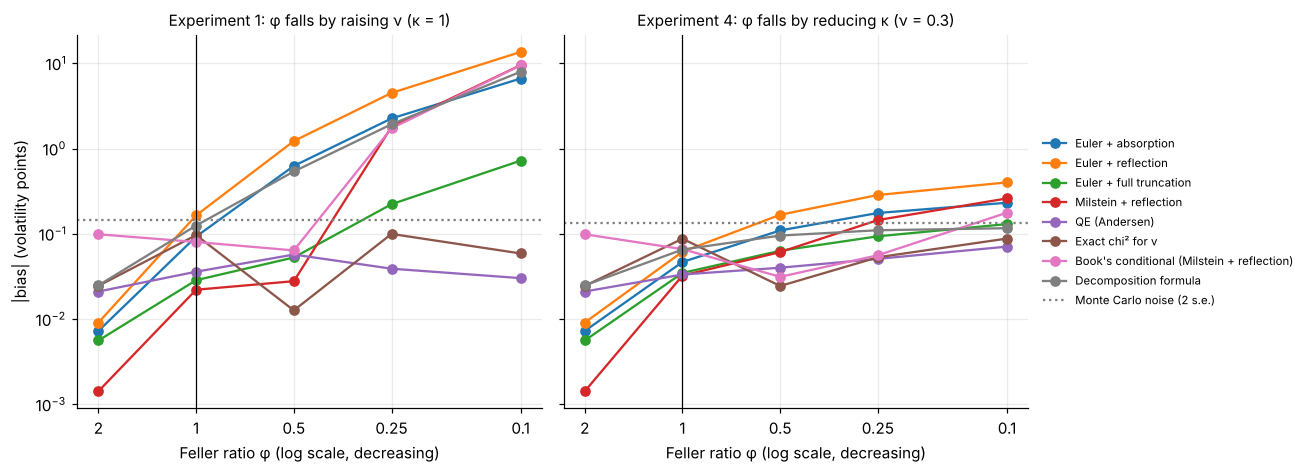

In [9]:
# The same φ, by two routes: raising ν (experiment 1) or reducing κ (experiment 4). Same colours for each method.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for a, res, title in [(ax[0], res1, "Experiment 1: φ falls by raising ν (κ = 1)"),
                      (ax[1], res4, "Experiment 4: φ falls by reducing κ (ν = 0.3)")]:
    for name, g in res.groupby("method", sort=False):
        a.plot(g["phi"], g["bias_vol"].abs(), "o-", label=name)   # |bias| of each method as a function of φ
    noise = 2 * res[res["method"] == "Exact chi² for v"]["se_vol"].mean()
    a.axhline(noise, color="gray", ls=":", label="Monte Carlo noise (2 s.e.)")
    a.axvline(1, color="k", lw=0.8)                                # φ = 1: Feller boundary
    a.set_xscale("log"); a.set_yscale("log"); a.invert_xaxis()
    a.set_xticks([2, 1, 0.5, 0.25, 0.1]); a.set_xticklabels(["2", "1", "0.5", "0.25", "0.1"]); a.minorticks_off()
    a.set_xlabel("Feller ratio φ (log scale, decreasing)"); a.set_title(title, fontsize=10)
ax[0].set_ylabel("|bias| (volatility points)")
ax[1].legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.savefig("fig_feller_kappa_vs_nu.png", dpi=150); plt.show()

## 7. Conclusions

**The answer to the question, in one sentence:** when the Feller condition does not hold, the Fourier formula, the exact simulation of the variance and Andersen's QE scheme keep working; Euler with full truncation works if enough steps are taken; and Euler with absorption or with reflection, Milstein with reflection and the book's conditional Monte Carlo have large biases when φ < 1/2.

**How it was measured.** Price of an ATM call (S0 = K = 100, T = 1, r = 0) with eight methods, compared with the Fourier price. All simulations use 200,000 paths and start with the same seed (`SEED = 1`). The Euler and Milstein schemes use exactly the same random numbers, so the differences between them do not come from simulation noise. The bias is measured in implied-volatility points and with z = bias / standard error: if |z| < 2, the bias cannot be distinguished from noise; if |z| is large, the method has a bias.

### 7.1 What happens to the variance when Feller does not hold

When φ < 1, zero is attainable: the density of v_T piles up near 0 (near zero it behaves like v^(φ−1), which blows up if φ < 1). With the book parameters, the probability that v_T is smaller than 0.001 is 0 with φ = 2, 1.3% with φ = 1, 9.3% with φ = 0.5 and 26.6% with φ = 0.25, while the mean of v_T does not change (0.0716). Since the process spends a lot of time near 0, which is exactly where discretisation schemes can give negative variances, numerical problems should be expected to grow as φ falls.

### 7.2 The Fourier formula does not need the Feller condition

If the Fourier formula failed when φ < 1, it would not coincide with the exact simulation of the variance, which has no discretisation error. Instead, for all ratios and in both experiments (1 and 4), the difference between the exact chi-squared and Fourier is at the noise level: |z| ≤ 1.5. It makes sense: the formula comes from the characteristic function, which is found by solving some differential (Riccati) equations that do not use the Feller condition anywhere. The condition only says whether v can touch zero, not whether the characteristic function exists. The only known numerical problem of the formula is the branch cut of the complex logarithm, and it is already solved by the "Little Heston Trap" formulation (Albrecher et al., 2007) that we use.

### 7.3 The exact chi-squared and the QE scheme have no bias

In experiment 1, the bias is between −0.10 and +0.06 points (chi-squared) and between 0.02 and 0.06 points (QE), with |z| < 1.5 for all φ. In experiment 2, it is at the noise level both with 12 steps and with 252. With the S&P 500 parameters (experiment 3) it is less than 0.11 points; the only slightly significant value is that of the chi-squared with weekly steps (0.11 points, z = 2.7), which comes from the trapezoidal rule for ∫v dt and disappears with daily steps (0.03 points, z = 0.8). Neither of the two schemes discretises the variance equation: the chi-squared generates v_{n+1} with its exact distribution, and QE with a distribution that has the same mean and the same variance and that, when the variance is near 0, has a probability mass at zero, like the real process when φ < 1. Since they never give negative values, nothing has to be "fixed".

### 7.4 Euler with full truncation: a small bias that becomes very small with daily steps

In experiment 1, the bias is 0.05 points with φ = 0.5, 0.22 with φ = 0.25 and 0.72 with φ = 0.1. In experiment 2 (φ = 0.25) it goes from 1.0 point with 12 steps to 0.22 with 52 and to 0.04 (z = 0.6, noise) with 104 or 252. With the S&P 500 parameters it is 1.16 points with weekly steps and 0.13 with daily steps (small, but still detectable: z = 3.2). The auxiliary process x can become negative, but only its positive part enters the square root and the drift (f₂ = f₃ = max(x, 0)): while x is negative, the variance applied to the price is 0 and the drift κθ pushes it up again. No variance is added artificially. Curiously, it is the scheme that becomes negative most often (22% of the steps with φ = 0.25) but the one with the smallest bias among those that correct negatives: what matters is not how many times x becomes negative, but how it is corrected (Lord, Koekkoek and van Dijk, 2010, reach the same conclusion).

### 7.5 Absorption, reflection, Milstein and the book's conditional Monte Carlo do not work when φ < 1/2

| Bias (volatility points) | φ = 2 | 1 | 0.5 | 0.25 | 0.1 | φ = 0.25, 252 steps | S&P 500, daily steps |
|---|---|---|---|---|---|---|---|
| Euler + absorption | 0.01 | 0.09 | 0.63 | 2.27 | 6.66 | 1.32 | 3.13 |
| Euler + reflection | 0.01 | 0.17 | 1.23 | 4.51 | 13.65 | 2.53 | 6.19 |
| Milstein + reflection | 0.00 | 0.02 | 0.03 | 1.81 | 9.55 | 1.11 | 3.44 |
| Book's conditional | −0.10 | −0.08 | −0.06 | 1.73 | 9.50 | 1.09 | 3.42 |

- **Euler with absorption and with reflection** (f₁ = f₂ = f₃ = max(x, 0) and |x|). When the Euler step comes out negative, absorption sets it to 0 and reflection takes its absolute value. Both corrections push the variance upwards every time it happens: the simulated variance ends up above the real one and the prices come out too high (positive biases). Reflection adds more (a −0.02 becomes +0.02 and not 0), and that is why its bias is twice as large. With φ = 0.25, Euler becomes negative in 8% of the steps, and taking more steps helps very little (with absorption, from 3.7 points with 12 steps to 1.3 with 252).
- **Milstein with reflection.** The Milstein step can be written as a square plus a term:

  v_{n+1} = (√v_n + ½ν√Δ·Z)² + (κθ − ν²/4)·Δ − κ·v_n·Δ.

  The square is never negative. If κθ ≥ ν²/4, that is, if **φ ≥ 1/2**, the second term is not negative either, and the step can only come out negative because of the small term −κv_nΔ (it happens in 1.2% of the steps with φ = 0.5, and by very little). That is why Milstein is perfect up to φ = 0.5 (0.03 points) and fails abruptly below it: with φ = 0.25 it comes out negative in 15% of the steps and the bias is 1.8 points. The threshold of Milstein is not φ = 1, but φ = 1/2.
- **The book's conditional Monte Carlo** simulates the variance with the same Milstein with reflection and inherits the same bias (1.73 points with φ = 0.25). Since it integrates the price with Black-Scholes, its standard error is much smaller than that of the other methods, which is why its z values are huge (115 with φ = 0.25 and 52 steps) with a bias in points similar to that of Milstein, and even the small normal error of Milstein with 52 steps comes out significant when Feller holds (−0.08 points, z ≈ −4). With the S&P 500 parameters the bias is 6.5 points with weekly steps and 3.4 with daily steps. This explains the z values from 16 to 123 in the ATM skew notebook: the bias came from the simulation method, not from the model.

### 7.6 Feller makes the bias appear, but its size is decided by ν (experiment 4)

With ν = 0.3 and φ = 0.1 (κ = 0.05), the biases are 0.23 points (absorption), 0.40 (reflection), 0.26 (Milstein), 0.18 (book's conditional) and 0.13 (full truncation). With the same φ = 0.1 but ν = 1.34 (experiment 1) they were 6.7, 13.7, 9.6, 9.5 and 0.72 points: between 5 and more than 50 times larger. Three conclusions:

- **Feller does matter:** with a small ν, the schemes that correct negatives still have a significant bias when φ is small (z between 2.1 and 12.6 with φ = 0.1), and the chi-squared and QE still have none.
- **But the size of the bias depends on ν:** the larger ν is, the larger the negative jumps that have to be corrected.
- **The decomposition formula has no problem with Feller:** with ν = 0.3, its error stays below 0.12 points even with φ = 0.1 (in experiment 1, with ν = 1.34, it was −8.0 points). What makes it fail is the large ν, and it makes sense: it is an approximation obtained by expanding in the volatility of volatility. That is why, with the S&P 500 parameters (ν ≈ 1.9), it misses the skew by 20% to 30% (ATM skew notebook).

With the S&P 500 data both things happen at the same time: φ ≈ 0.2 (Feller badly violated) and ν ≈ 1.9 (very large). It is the worst case for the schemes with absorption or reflection and for the decomposition formula.

### 7.7 What it means for the thesis

- The calibration and the ATM skew can be computed with Fourier even if Feller does not hold. There is no need to impose the condition in the calibration.
- To check prices with Monte Carlo, the QE scheme or the exact chi-squared must be used (about 12 seconds with 200,000 paths and daily steps over a quarter), or Euler with full truncation and daily steps. The book's conditional Monte Carlo must not be used as it is, nor any scheme with absorption or reflection.
- The error of the decomposition formula with real data is a problem of large ν, not of Feller.

### 7.8 Limitations

- Only one option (ATM call) and two maturities (1 year and 3 months). Deep out-of-the-money options could be more sensitive to the paths with small variance.
- QE has been programmed without Andersen's martingale correction, and the "exact chi-squared" is only exact for the variance: ∫v dt is approximated by the trapezoidal rule (it is not the complete exact simulation of Broadie and Kaya).
- A single random seed: the biases are judged with z, but with a single repetition of each experiment.
- To separate Feller from ν, only κ has been reduced; θ could also be reduced.

## 8. References

- Albrecher, H., Mayer, P., Schoutens, W. and Tistaert, J. (2007). The little Heston trap. *Wilmott Magazine*, January, 83–92. (The Fourier formula without branch cuts.)
- Alòs, E. (2012). A decomposition formula for option prices in the Heston model and applications to option pricing approximation. *Finance and Stochastics*, 16(3), 403–422. (The decomposition formula.)
- Alòs, E. and Ewald, C.-O. (2008). Malliavin differentiability of the Heston volatility and applications to option pricing. *Advances in Applied Probability*, 40(1), 144–162.
- Andersen, L. (2008). Simple and efficient simulation of the Heston stochastic volatility model. *Journal of Computational Finance*, 11(3), 1–42. (The QE scheme, the threshold ψ_c = 1.5 and the price step, equation 33.)
- Broadie, M. and Kaya, Ö. (2006). Exact simulation of stochastic volatility and other affine jump diffusion processes. *Operations Research*, 54(2), 217–231. (Exact simulation.)
- Cox, J. C., Ingersoll, J. E. and Ross, S. A. (1985). A theory of the term structure of interest rates. *Econometrica*, 53(2), 385–407. (The variance process.)
- Feller, W. (1951). Two singular diffusion problems. *Annals of Mathematics*, 54(1), 173–182. (The origin of the condition.)
- Glasserman, P. (2003). *Monte Carlo Methods in Financial Engineering.* Springer, section 3.4. (The non-central chi-squared distribution of the variance and how to simulate it.)
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *Review of Financial Studies*, 6(2), 327–343.
- Lord, R., Koekkoek, R. and van Dijk, D. (2010). A comparison of biased simulation schemes for stochastic volatility models. *Quantitative Finance*, 10(2), 177–194. (Absorption, reflection and full truncation: the functions f₁, f₂, f₃.)